In [1]:
import sys
import os
import json


sys.path.append(os.path.join(os.getcwd(), '../../src/'))
from utils_mouse import read_utils

sys.path.append(os.path.join(os.getcwd(), '../../../../'))
from utils import plot_utils
from utils import train_utils

In [2]:
import importlib
importlib.reload(read_utils)
importlib.reload(plot_utils)
importlib.reload(train_utils)

<module 'utils.train_utils' from '/home/julian-zim/Files/Cloud/OneDrive/OneFiles/Linux/ZimmerLab/MSc_Thesis/Workspace/hobe/utils/train_utils.py'>

In [3]:
ll = 'll00'
data_variant = 'gcamp'
model_variant = 'ns'
organism = 'mouse-2019-stringer'

In [4]:
# file_ids = list(range(0, 12+1))
file_ids = [2]

path = os.path.join(read_utils.get_data_path(), '6163622/sessions')
filenames = [read_utils.get_filename(read_utils.get_filepath(path, file_id)) for file_id in file_ids]

In [5]:
manual = False

if manual:
	with open('../../hyperparams_manual.json', 'r') as f:
		reg_lambdas = json.load(f)
else:
	with open('../../hyperparams.json', 'r') as f:
		reg_lambdas = json.load(f)['geometric'][ll]

bom_folder = (f'{data_variant}_bom_{model_variant}_'
			  + '_'.join([f'{param.split('_')[0]}{reg_lambdas[model_variant]['bom'][param]:.2E}' for param in reg_lambdas[model_variant]['bom'].keys()]))
hgm_folder = (f'{data_variant}_hgm_{model_variant}_'
			  + '_'.join([f'{param.split('_')[0]}{reg_lambdas[model_variant]['hgm'][param]:.2E}' for param in reg_lambdas[model_variant]['hgm'].keys()]))

# losses

In [6]:
boms_losses = [train_utils.load_losses(os.path.join(read_utils.get_model_path(), 'history', bom_folder), filename) for filename in filenames]
boms_losses_train = [losses[0] for losses in boms_losses]
boms_man_losses_train = [losses[1] for losses in boms_losses]
boms_res_losses_train = [losses[2] for losses in boms_losses]
boms_mpe_losses_train = [losses[3] for losses in boms_losses]
boms_losses_test = [losses[4] for losses in boms_losses]
boms_man_losses_test = [losses[5] for losses in boms_losses]
boms_res_losses_test = [losses[6] for losses in boms_losses]
boms_mpe_losses_test = [losses[7] for losses in boms_losses]

hgms_losses = [train_utils.load_losses(os.path.join(read_utils.get_model_path(), 'history', hgm_folder), filename) for filename in filenames]
hgms_losses_train = [losses[0] for losses in hgms_losses]
hgms_man_losses_train = [losses[1] for losses in hgms_losses]
hgms_res_losses_train = [losses[2] for losses in hgms_losses]
hgms_mpe_losses_train = [losses[3] for losses in hgms_losses]
hgms_losses_test = [losses[4] for losses in hgms_losses]
hgms_man_losses_test = [losses[5] for losses in hgms_losses]
hgms_res_losses_test = [losses[6] for losses in hgms_losses]
hgms_mpe_losses_test = [losses[7] for losses in hgms_losses]

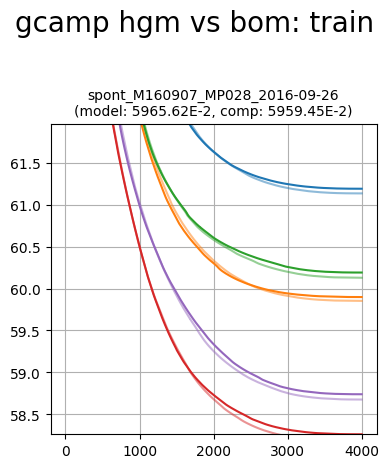

In [16]:
plot_utils.plot_losses_splits(filenames,
							  hgms_losses_train, boms_losses_train,
							  title='gcamp hgm vs bom: train',
							  ylimits=0.00006)

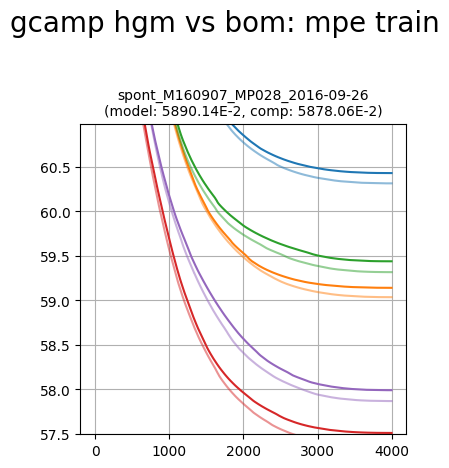

In [24]:
plot_utils.plot_losses_splits(filenames,
							  hgms_mpe_losses_train, boms_mpe_losses_train,
							  title='gcamp hgm vs bom: mpe train',
							  ylimits=0.15)

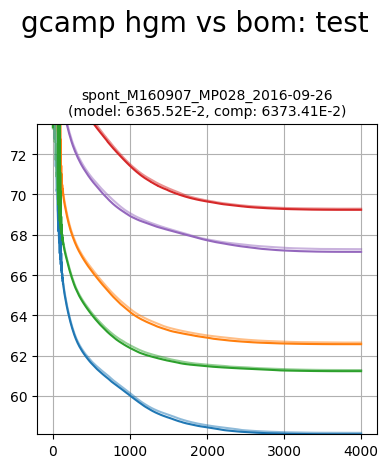

In [30]:
plot_utils.plot_losses_splits(filenames,
							  hgms_losses_test, boms_losses_test,
							  title='gcamp hgm vs bom: test',
							  ylimits=0.00025)

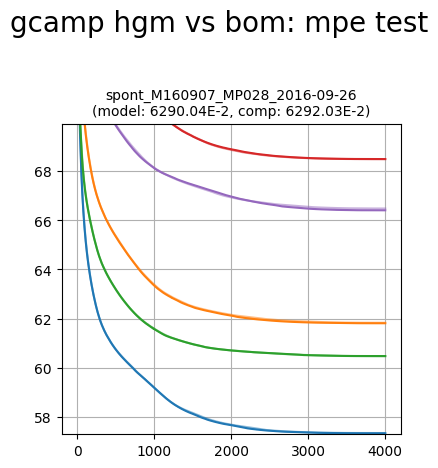

In [36]:
plot_utils.plot_losses_splits(filenames,
							  hgms_mpe_losses_test, boms_mpe_losses_test,
							  title='gcamp hgm vs bom: mpe test',
							  ylimits=0.4)